In [20]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)
warnings.filterwarnings("ignore")  
os.makedirs("results")                           

In [21]:
df = pd.read_csv("data/bank-full.csv", sep=";")
 
print("Shape (rows, columns):", df.shape)
print()
print(df.head())
print()
df.info()


Shape (rows, columns): (45211, 17)

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data colu

     count  percent
y                  
no   39922     88.3
yes   5289     11.7

Imbalance ratio (majority : minority) = 7.55 : 1
A 'dumb' model that always says 'no' would score 88.30% accuracy


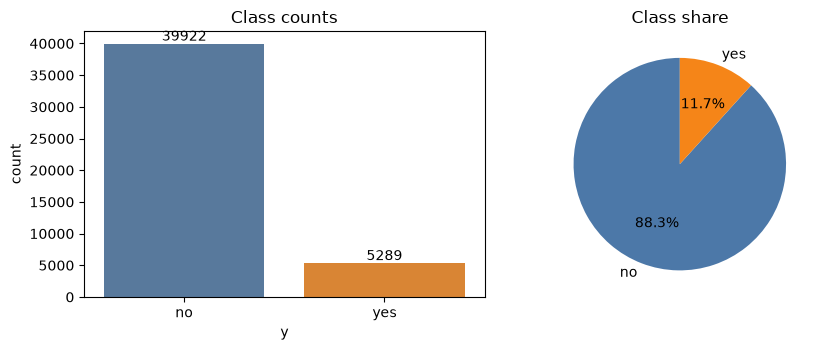

In [22]:
TARGET = "y"
counts = df[TARGET].value_counts()
percent = df[TARGET].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": counts, "percent": percent}))
print()
print(f"Imbalance ratio (majority : minority) = {counts.max()/counts.min():.2f} : 1")
print(f"A 'dumb' model that always says 'no' would score {counts.max()/counts.sum():.2%} accuracy")
 
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
sns.countplot(x=TARGET, data=df, order=["no", "yes"], palette=["#4C78A8", "#F58518"], ax=ax[0])
ax[0].set_title("Class counts")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                   ha="center", va="bottom")
ax[1].pie(counts[["no", "yes"]], labels=["no", "yes"], autopct="%.1f%%",
          colors=["#4C78A8", "#F58518"], startangle=90)
ax[1].set_title("Class share")
plt.tight_layout()
plt.savefig("results/01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


In [23]:
num_cols = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
cat_cols = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
 
print(f"{len(num_cols)} numeric features    :", num_cols)
print(f"{len(cat_cols)} categorical features:", cat_cols)
print(f"Total input features: {len(num_cols)+len(cat_cols)}  (assignment needs >= 12)")
print(f"Total instances     : {len(df)}  (assignment needs >= 1000)")
print()
print("---- numeric summary ----")
print(df[num_cols].describe().T.round(1))
print()
print("---- categorical: number of distinct values ----")
print(df[cat_cols].nunique().sort_values(ascending=False))


7 numeric features    : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
9 categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Total input features: 16  (assignment needs >= 12)
Total instances     : 45211  (assignment needs >= 1000)

---- numeric summary ----
            count    mean     std     min    25%    50%     75%       max
age       45211.0    40.9    10.6    18.0   33.0   39.0    48.0      95.0
balance   45211.0  1362.3  3044.8 -8019.0   72.0  448.0  1428.0  102127.0
day       45211.0    15.8     8.3     1.0    8.0   16.0    21.0      31.0
duration  45211.0   258.2   257.5     0.0  103.0  180.0   319.0    4918.0
campaign  45211.0     2.8     3.1     1.0    1.0    2.0     3.0      63.0
pdays     45211.0    40.2   100.1    -1.0   -1.0   -1.0    -1.0     871.0
previous  45211.0     0.6     2.3     0.0    0.0    0.0     0.0     275.0

---- categorical: number of distinct values ----
job        

In [24]:
#Missing values
print("Real NaN cells:", int(df.isna().sum().sum()))

unknown_cnt = (df[cat_cols] == "unknown").sum()
unknown_cnt = unknown_cnt[unknown_cnt > 0]
report = pd.DataFrame({"unknown_count": unknown_cnt,"unknown_percent": (unknown_cnt/len(df)*100).round(2)})
print(report)
print()
df[cat_cols] = df[cat_cols].replace("unknown", np.nan)
print(df.isna().sum()[df.isna().sum() > 0])


Real NaN cells: 0
           unknown_count  unknown_percent
job                  288             0.64
education           1857             4.11
contact            13020            28.80
poutcome           36959            81.75

job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


In [25]:
drop_cols = ["education", "contact", "poutcome"]
df = df.drop(columns=drop_cols)
df = df.dropna(subset=["job"]).reset_index(drop=True)
cat_cols = [c for c in cat_cols if c not in drop_cols]

print("Shape now:", df.shape) 
print("Missing cells left:", int(df.isna().sum().sum()))

Shape now: (44923, 14)
Missing cells left: 0


In [26]:
#Duplicates
n_dup = df.duplicated().sum()
print("Exact duplicate rows found:", n_dup)
 
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before}   rows after: {len(df)}   removed: {before-len(df)}")

Exact duplicate rows found: 0
Rows before: 44923   rows after: 44923   removed: 0


In [27]:
#Train / test split (80:20)
RANDOM_STATE = 42
X = df.drop(columns=TARGET)
y = df[TARGET].map({"no": 0, "yes": 1})
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)
 
print("Train:", X_train.shape, "  Test:", X_test.shape)
print()
print(pd.DataFrame({
    "full":  y.value_counts(normalize=True).mul(100).round(2),
    "train": y_train.value_counts(normalize=True).mul(100).round(2),
    "test":  y_test.value_counts(normalize=True).mul(100).round(2)}).rename_axis("class (1=yes)"))
 
# Save the raw test set (features + label) - the assignment asks for the test csv in the repo
test_out = X_test.copy(); test_out[TARGET] = y_test.map({0: "no", 1: "yes"})
test_out.to_csv("data/test_data.csv", index=False)


Train: (35938, 13)   Test: (8985, 13)

               full  train  test
class (1=yes)                   
0              88.3   88.3  88.3
1              11.7   11.7  11.7


In [28]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale",  StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)

feat_names = preprocessor.get_feature_names_out()
print("Train matrix:", X_train_p.shape, "  Test matrix:", X_test_p.shape)

scaler = preprocessor.named_transformers_["num"].named_steps["scale"]
print(pd.DataFrame({"mean learned from TRAIN": scaler.mean_,"mean of FULL data": df[num_cols].mean().values}, index=num_cols).round(2))

Train matrix: (35938, 39)   Test matrix: (8985, 39)
          mean learned from TRAIN  mean of FULL data
age                         40.88              40.89
balance                   1366.65            1359.64
day                         15.81              15.81
duration                   258.68             258.29
campaign                     2.76               2.76
pdays                       40.37              40.32
previous                     0.58               0.58


In [29]:
models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                                                  random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                  random_state=RANDOM_STATE, n_jobs=-1),
}


In [30]:
def evaluate(model, Xtr, ytr, Xte, yte):
    """Fit on train, score on test. Returns metrics dict + predictions."""
    model.fit(Xtr, ytr)
    y_pred = model.predict(Xte)                  # hard label: 0 or 1
    y_prob = model.predict_proba(Xte)[:, 1]      # soft score: P(class = yes)
    return {
        "Accuracy":  accuracy_score(yte, y_pred),
        "AUC":       roc_auc_score(yte, y_prob),         # needs probabilities, not labels
        "Precision": precision_score(yte, y_pred),
        "Recall":    recall_score(yte, y_pred),
        "F1":        f1_score(yte, y_pred),
        "MCC":       matthews_corrcoef(yte, y_pred),
    }, y_pred, y_prob
 
rows, preds, probs, train_acc = {}, {}, {}, {}
for name, model in models.items():
    rows[name], preds[name], probs[name] = evaluate(model, X_train_p, y_train, X_test_p, y_test)
    train_acc[name] = accuracy_score(y_train, model.predict(X_train_p))
    print(f"trained {name}")
 
results = pd.DataFrame(rows).T.round(4)
results.index.name = "Model"
results.to_csv("results/model_comparison.csv")
print()
print(results)


trained Logistic Regression
trained Decision Tree
trained K-Nearest Neighbors
trained Naive Bayes (Gaussian)
trained Random Forest

                        Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                      
Logistic Regression       0.8939  0.8883     0.6017  0.2759  0.3783  0.3591
Decision Tree             0.8918  0.8676     0.5542  0.3844  0.4539  0.4042
K-Nearest Neighbors       0.8936  0.8713     0.6017  0.2674  0.3702  0.3532
Naive Bayes (Gaussian)    0.8558  0.7978     0.3928  0.4272  0.4093  0.3277
Random Forest             0.9016  0.9220     0.6299  0.3853  0.4782  0.4431


In [31]:
print(results.to_string())
print()
print("Best model per metric:")
print(results.idxmax().to_string())
 
print()
gap = pd.DataFrame({"train_accuracy": pd.Series(train_acc).round(4),
                    "test_accuracy": results["Accuracy"]})
gap["gap (overfit?)"] = (gap["train_accuracy"] - gap["test_accuracy"]).round(4)
print("Overfitting check (train vs test accuracy):")
print(gap)


                        Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                      
Logistic Regression       0.8939  0.8883     0.6017  0.2759  0.3783  0.3591
Decision Tree             0.8918  0.8676     0.5542  0.3844  0.4539  0.4042
K-Nearest Neighbors       0.8936  0.8713     0.6017  0.2674  0.3702  0.3532
Naive Bayes (Gaussian)    0.8558  0.7978     0.3928  0.4272  0.4093  0.3277
Random Forest             0.9016  0.9220     0.6299  0.3853  0.4782  0.4431

Best model per metric:
Accuracy              Random Forest
AUC                   Random Forest
Precision             Random Forest
Recall       Naive Bayes (Gaussian)
F1                    Random Forest
MCC                   Random Forest

Overfitting check (train vs test accuracy):
                        train_accuracy  test_accuracy  gap (overfit?)
Logistic Regression             0.8933         0.8939         -0.0006
Decision Tree                   0.9097     

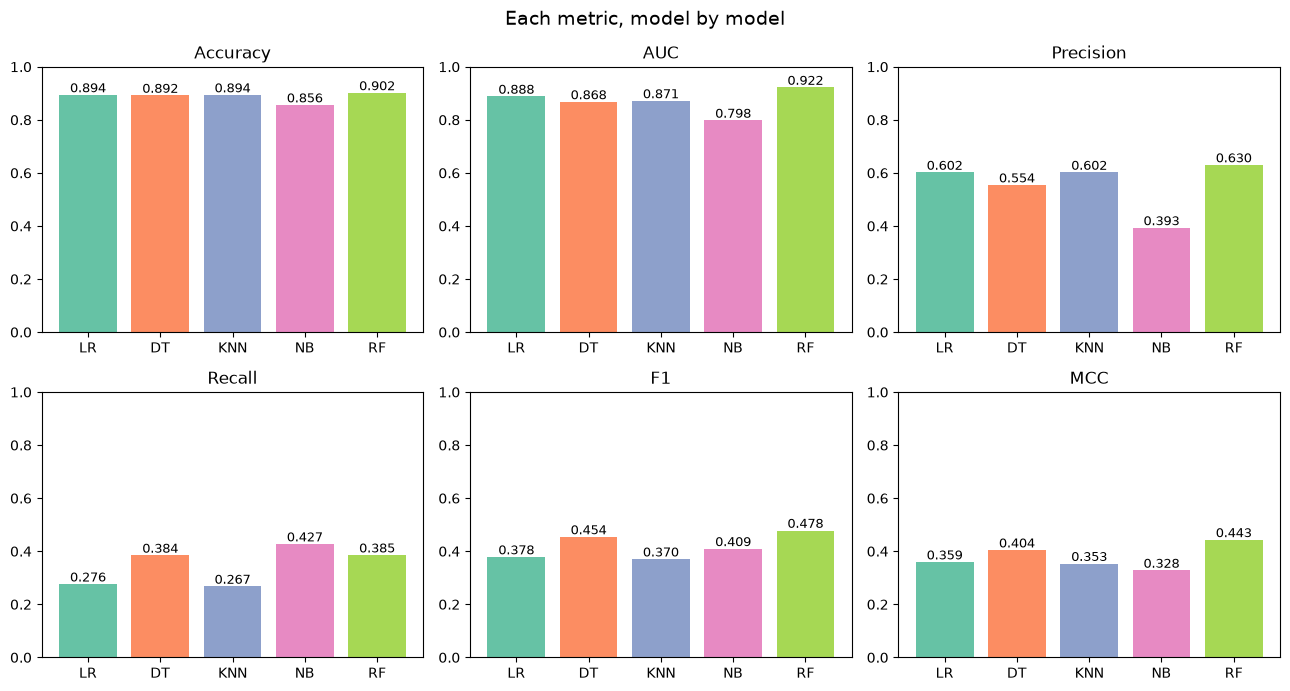

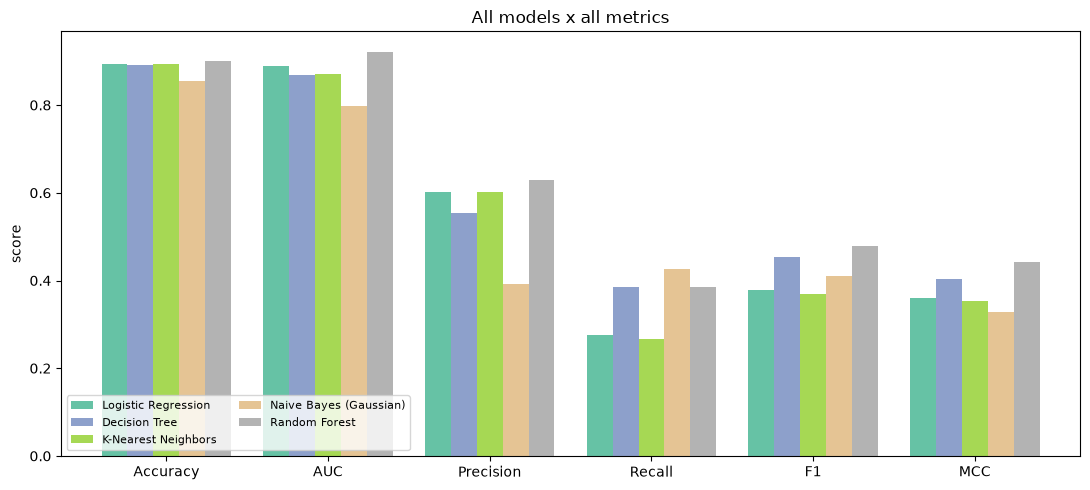

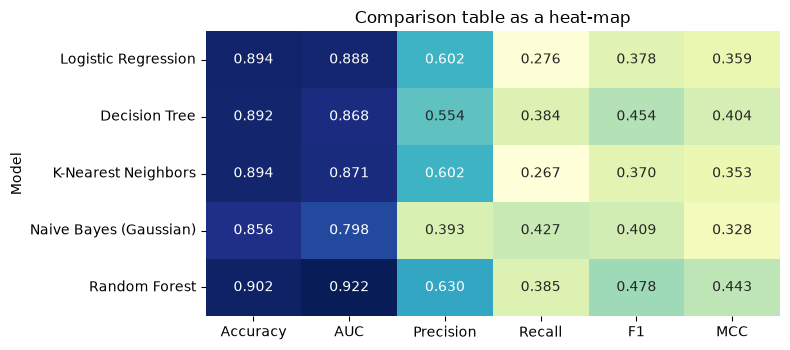

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
palette = sns.color_palette("Set2", len(results))
for ax, metric in zip(axes.ravel(), results.columns):
    ax.bar(range(len(results)), results[metric], color=palette)
    ax.set_title(metric); ax.set_xticks(range(len(results)))
    ax.set_xticklabels(["LR", "DT", "KNN", "NB", "RF"])
    lo = min(0, results[metric].min() - 0.05)
    ax.set_ylim(lo, 1.0)
    for i, v in enumerate(results[metric]):
        ax.text(i, v + (0.01 if v >= 0 else -0.06), f"{v:.3f}", ha="center", fontsize=9)
plt.suptitle("Each metric, model by model", fontsize=14)
plt.tight_layout()
plt.savefig("results/03_metric_bars.png", dpi=150, bbox_inches="tight")
plt.show()
 
ax = results.T.plot(kind="bar", figsize=(11, 5), width=0.8, colormap="Set2")
ax.set_title("All models x all metrics"); ax.set_ylabel("score"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.legend(loc="lower left", fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("results/04_grouped_metrics.png", dpi=150, bbox_inches="tight")
plt.show()
 
plt.figure(figsize=(8, 3.6))
sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu", cbar=False)
plt.title("Comparison table as a heat-map")
plt.tight_layout()
plt.savefig("results/05_metric_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


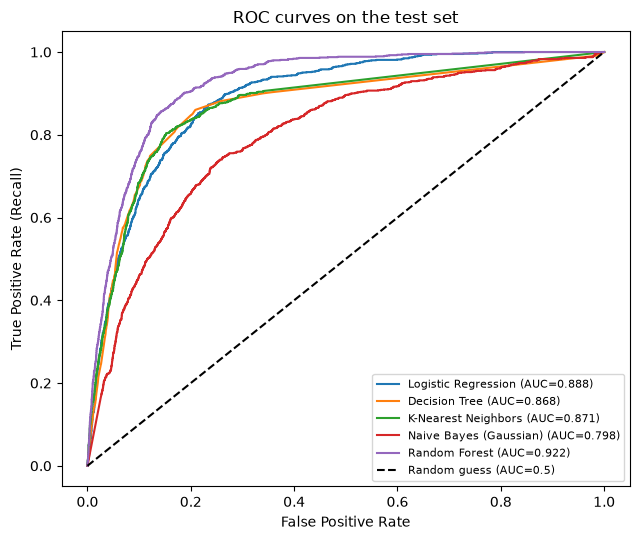

In [33]:
plt.figure(figsize=(6.5, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC=0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves on the test set"); plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("results/06_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()


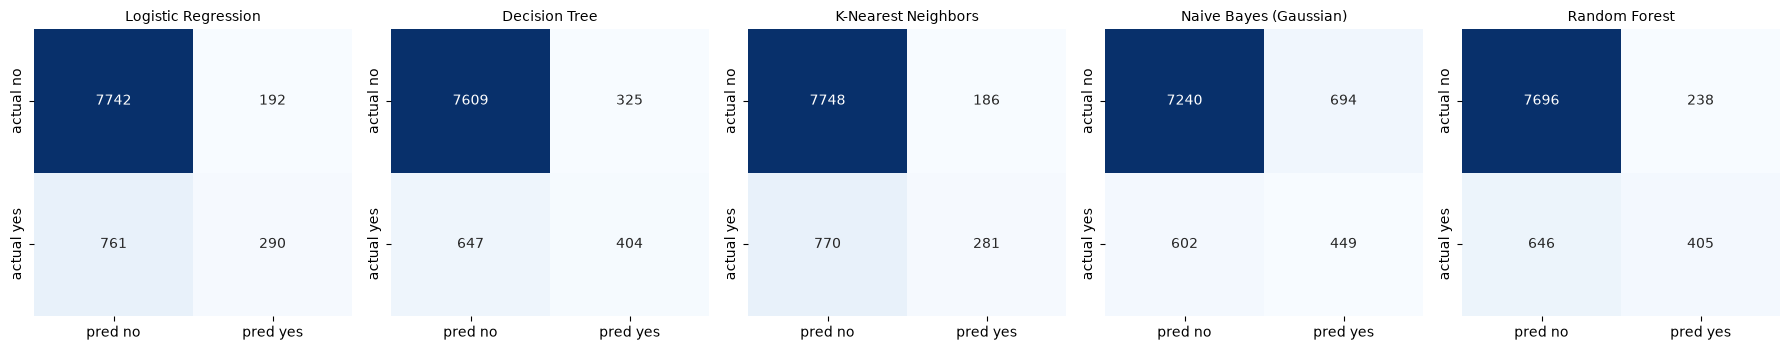

Random Forest confusion matrix -> TN: 7696  FP: 238  FN: 646  TP: 405
Precision = TP/(TP+FP) = 405 / 643 = 0.6299
Recall    = TP/(TP+FN) = 405 / 1051 = 0.3853


In [34]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred no", "pred yes"], yticklabels=["actual no", "actual yes"])
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig("results/07_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
 
tn, fp, fn, tp = confusion_matrix(y_test, preds["Random Forest"]).ravel()
print("Random Forest confusion matrix -> TN:", tn, " FP:", fp, " FN:", fn, " TP:", tp)
print("Precision = TP/(TP+FP) =", tp, "/", tp+fp, "=", round(tp/(tp+fp), 4))
print("Recall    = TP/(TP+FN) =", tp, "/", tp+fn, "=", round(tp/(tp+fn), 4))


In [35]:
results.reset_index().to_csv("results/model_comparison.csv", index=False)
print(open("results/model_comparison.csv").read())
print("Files in results/:", sorted(os.listdir("results")))
print("Files in data/   :", sorted(os.listdir("data")))


Model,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8939,0.8883,0.6017,0.2759,0.3783,0.3591
Decision Tree,0.8918,0.8676,0.5542,0.3844,0.4539,0.4042
K-Nearest Neighbors,0.8936,0.8713,0.6017,0.2674,0.3702,0.3532
Naive Bayes (Gaussian),0.8558,0.7978,0.3928,0.4272,0.4093,0.3277
Random Forest,0.9016,0.922,0.6299,0.3853,0.4782,0.4431

Files in results/: ['01_class_distribution.png', '03_metric_bars.png', '04_grouped_metrics.png', '05_metric_heatmap.png', '06_roc_curves.png', '07_confusion_matrices.png', 'model_comparison.csv']
Files in data/   : ['bank-full.csv', 'test_data.csv']
